# Today’s occupancy: 08:00 → midnight

Compare the previous eight weeks’ same-weekday/time average with **all four Timestral sizes**, without choosing a winner. Every forecast is made once, at **08:00 Europe/Vienna**, from readings strictly before that cutoff. Forecasts are 64 fifteen-minute averages.

This notebook reads the SQLite database without modifying it. Model weights (~1.46 GB total) download on the first run. Models run sequentially on CPU in isolated processes; forecasts and measurements are cached under `results/`. See the repository README for setup. Official model API: https://github.com/mistralai/timestral.

In [1]:
from pathlib import Path
import sys

# Works when Jupyter starts in the repository root or in notebooks/.
NOTEBOOK_DIR = Path.cwd().resolve()
if not (NOTEBOOK_DIR / "forecast_benchmark.py").exists():
    NOTEBOOK_DIR = NOTEBOOK_DIR / "notebooks"
sys.path.insert(0, str(NOTEBOOK_DIR))

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from forecast_benchmark import (
    BASELINE, MODELS, METHODS, Config, read_history, prepare, case_coverage,
    freeze_experiment, run_split, finalize_validation, score, leaderboard,
    balanced_mean, paired_intervals, plot_tradeoff, plot_examples,
)

pd.set_option("display.max_columns", 20)
pd.set_option("display.precision", 3)
DATABASE = NOTEBOOK_DIR.parent / "backend" / "data" / "boulderbat.db"
CONFIG = Config(threads=4, bootstrap_samples=2000, seed=42, end_date=None)
# Set end_date="YYYY-MM-DD" to reproduce a particular exclusive local end date.
# These immutable upstream checkpoint revisions are shared by validation and test.
REVISIONS = {
    "Timestral-5M": "bdd20cfc15a3fea0e4cb5ccef37f8d3ca7aa335f",
    "Timestral-28M": "49b26409ac87b5935539a5d8ffe7f397b720db47",
    "Timestral-123M": "5a147287addda85f6acd8da3fb8858fe9af7e8f7",
    "Timestral-209M": "9874d252ab0aae16f7f7c999f98f98d6ad7d8365",
}
RESULT_COLUMNS = ["status", "mae_pp", "improvement_vs_baseline_pct", "bias_pp",
                  "coverage_80", "width_80_pp", "median_inference_ms", "p95_inference_ms",
                  "load_seconds", "download_seconds", "peak_process_ram_mb", "artifact_mb"]

## 1. Data quality and evaluation dates

The latest 28 completed local days form the test period; the preceding 28 form validation. The last observed 15-minute bin determines how far the snapshot extends, capped at today’s local midnight. An explicit end date cannot include a partial/future day.

Resampling uses left-closed UTC bins, so a context bin ends no later than 08:00. Local weekday/time matching preserves the seasonal baseline across daylight-saving changes. All eight weeks remain in the model context, including nights and missing bins. The baseline gives each available weekly slot equal weight. This uses quarter-hour slots rather than the app’s existing hourly display.

A gym/day needs eight weeks of elapsed history and at least one observed target with baseline support. There is no hidden completeness filter: sparse bins, missing targets, missing baseline support, and excluded gym/days are reported. A partial bin’s target is its observed readings’ average; missing targets are never interpolated. Coverage is not proof that an upstream sensor was updating.

In [2]:
history, locations, ingestion_report = read_history(DATABASE)
cases, quality, exclusions, periods = prepare(history, locations, CONFIG)
coverage = case_coverage(cases)
print("Database:", DATABASE)
print("Data cleanup:", ingestion_report)
print("Evaluation periods (local dates):", periods)
display(quality)
display(coverage.groupby("split").agg(
    gym_days=("day", "size"), gyms=("location", "nunique"), days=("day", "nunique"),
    mean_context_coverage=("context_coverage", "mean"),
    observed_target_bins=("observed_target_bins", "sum"),
    scored_target_bins=("scored_target_bins", "sum"),
    missing_baseline_bins=("missing_baseline_bins_with_observations", "sum"),
    partial_target_bins=("partially_observed_target_bins", "sum"),
))
if not exclusions.empty:
    display(exclusions.groupby(["location", "reason"]).size().rename("excluded_days").to_frame())
else:
    print("No excluded gym/days.")
# Includes individual exclusions and per-case coverage, not only totals.
RUN_DIR = freeze_experiment(NOTEBOOK_DIR / "results", DATABASE, CONFIG, cases, periods, REVISIONS)
quality.to_csv(RUN_DIR / "data_quality.csv", index=False)
coverage.to_csv(RUN_DIR / "case_coverage.csv", index=False)
exclusions.to_csv(RUN_DIR / "exclusions.csv", index=False)
print("Reproducible experiment:", RUN_DIR)

Database: /Users/flo/src/boulderbat/backend/data/boulderbat.db
Data cleanup: {'duplicate_rows_removed': 7, 'invalid_values_masked': 0}
Evaluation periods (local dates): {'validation_start': '2026-08-28', 'test_start': '2026-09-25', 'end_exclusive': '2026-10-23'}


,location,first_reading,last_reading,earliest_08_forecast,raw_readings,empty_15min_bins,partially_observed_bins,eligible_days
0,Linz,2026-05-17 18:16:03+02:00,2026-10-22 23:59:54+02:00,2026-07-13 08:00:00+02:00,47517,55,31,56
1,Salzburg,2026-05-17 18:16:03+02:00,2026-10-22 23:59:54+02:00,2026-07-13 08:00:00+02:00,47517,55,31,56
2,Hannovergasse,2026-05-17 18:16:03+02:00,2026-10-22 23:59:54+02:00,2026-07-13 08:00:00+02:00,47517,55,31,56
3,Hauptbahnhof,2026-05-17 18:16:03+02:00,2026-10-22 23:59:54+02:00,2026-07-13 08:00:00+02:00,47517,55,31,56
4,Seestadt,2026-05-17 18:16:03+02:00,2026-10-22 23:59:54+02:00,2026-07-13 08:00:00+02:00,47517,55,31,56
5,Wienerberg,2026-05-17 18:16:03+02:00,2026-10-22 23:59:54+02:00,2026-07-13 08:00:00+02:00,47517,55,31,56
6,St. Pölten,2026-05-17 18:16:03+02:00,2026-10-22 23:59:54+02:00,2026-07-13 08:00:00+02:00,47517,55,31,56
7,Blockfabrik,2026-08-28 23:39:53+02:00,2026-10-23 01:09:54+02:00,2026-10-24 08:00:00+02:00,15817,7,27,0


,gym_days,gyms,days,mean_context_coverage,observed_target_bins,scored_target_bins,missing_baseline_bins,partial_target_bins
split,,,,,,,,
test,196,7,28,0.999,12544,12544,0,7
validation,196,7,28,1.000,12544,12544,0,42


,,excluded_days
location,reason,
Blockfabrik,Less than eight weeks of preceding history,56


Reproducible experiment: /Users/flo/src/boulderbat/notebooks/results/86d61981513e9be6


## 2. Validate first

The configuration, data hash, implementation, dependency lock, model revisions, and case order are recorded in `manifest.json`. Changing them creates a new result directory, so stale predictions cannot be silently reused.

Each Timestral size receives the **same univariate gym/day inputs**, batch size one, CPU float32, and fixed thread count. No fine-tuning, weather, holiday, or other covariates are added. Native missing-value handling and default forecast options are retained. Point estimates use the median; the 80% interval uses the 10th and 90th percentiles. We do not manually clip or round forecasts.

Timing excludes one warm-up forecast and separates download/cache lookup, model loading, and inference. Peak process RAM includes Python, PyTorch, download/cache lookup, model loading, warm-up, and inference; it is measured in a fresh process per model/split. Artifact size is downloaded config + weight bytes, independent of cache warmth. The baseline’s aggregation happens during preparation, so its inference/RAM comparison is left blank rather than presented as comparable model inference.

In [3]:
validation_cases, validation_predictions, validation_runtime = run_split(
    RUN_DIR, cases, "validation", REVISIONS, CONFIG
)
validation_scores = score(validation_cases, validation_predictions)
validation_table = leaderboard(validation_scores, validation_runtime)
display(validation_table.reindex(columns=RESULT_COLUMNS))
if "error" in validation_runtime:
    display(validation_runtime["error"].dropna())
validation_scores.to_csv(RUN_DIR / "validation_scores.csv", index=False)
validation_table.drop(columns=["inference_ms", "versions"], errors="ignore").to_csv(RUN_DIR / "validation_results.csv")

validation: Weekday average (8 weeks) (196 gym/days)


validation: Timestral-5M (196 gym/days)


validation: Timestral-28M (196 gym/days)


validation: Timestral-123M (196 gym/days)


validation: Timestral-209M (196 gym/days)


,status,mae_pp,improvement_vs_baseline_pct,bias_pp,coverage_80,width_80_pp,median_inference_ms,p95_inference_ms,load_seconds,download_seconds,peak_process_ram_mb,artifact_mb
method,,,,,,,,,,,,
Weekday average (8 weeks),ok,4.145,0.000,-0.664,NaN,NaN,NaN,NaN,0.0,0.0,NaN,0.0
Timestral-5M,ok,4.463,-7.679,-0.786,0.830,15.055,14.584,15.347,0.037,2.304,412.697,20.845
Timestral-28M,ok,4.345,-4.838,-0.765,0.834,14.689,46.967,48.183,0.074,3.766,649.576,111.297
Timestral-123M,ok,3.939,4.968,-0.688,0.836,13.391,119.498,122.239,0.33,13.415,1788.428,490.447
Timestral-209M,ok,3.966,4.321,-0.762,0.826,13.464,166.479,169.223,0.552,21.265,2791.457,837.273


Inspect the validation results and data coverage before using test results. If data preparation or settings need changing, change them above and rerun validation. The next cell only permits testing after every method has produced valid forecasts on the identical validation targets; any failed model remains visible in the table and blocks the test phase.

In [4]:
finalize_validation(RUN_DIR, validation_runtime)
print("Validation complete. Settings frozen for this experiment.")

Validation complete. Settings frozen for this experiment.


## 3. Final test results

Every method is scored on exactly the same observed target bins with baseline support. Nonfinite model outputs on those bins are treated as a failure, never removed to improve a model’s score.

MAE and signed error are in **occupancy percentage points**; signed error is predicted minus observed. We average bins within each gym/day, days within each gym, then gyms equally. Positive improvement means a lower MAE than the eight-week baseline. Interval coverage should be interpreted alongside interval width, with 0.80 as the nominal target. No model is selected automatically.

In [5]:
test_cases, test_predictions, test_runtime = run_split(RUN_DIR, cases, "test", REVISIONS, CONFIG)
test_scores = score(test_cases, test_predictions)
test_table = leaderboard(test_scores, test_runtime)
display(test_table.reindex(columns=RESULT_COLUMNS))
if "error" in test_runtime:
    display(test_runtime["error"].dropna())
test_scores.to_csv(RUN_DIR / "test_scores.csv", index=False)
test_table.drop(columns=["inference_ms", "versions"], errors="ignore").to_csv(RUN_DIR / "test_results.csv")

test: Weekday average (8 weeks) (196 gym/days)


test: Timestral-5M (196 gym/days)


test: Timestral-28M (196 gym/days)


test: Timestral-123M (196 gym/days)


test: Timestral-209M (196 gym/days)


,status,mae_pp,improvement_vs_baseline_pct,bias_pp,coverage_80,width_80_pp,median_inference_ms,p95_inference_ms,load_seconds,download_seconds,peak_process_ram_mb,artifact_mb
method,,,,,,,,,,,,
Weekday average (8 weeks),ok,4.559,0.000,-1.324,NaN,NaN,NaN,NaN,0.0,0.0,NaN,0.0
Timestral-5M,ok,4.533,0.581,-1.316,0.834,15.016,14.579,15.275,0.041,0.038,332.743,20.845
Timestral-28M,ok,4.345,4.692,-1.404,0.842,14.815,46.739,47.733,0.159,0.039,514.327,111.297
Timestral-123M,ok,4.060,10.958,-1.397,0.832,12.970,118.431,120.294,0.623,0.04,1274.053,490.447
Timestral-209M,ok,4.070,10.737,-1.507,0.836,13.297,166.968,168.921,0.603,0.04,1970.405,837.273


In [6]:
# Daily scores retain equal day weights; no weighting by number of raw readings.
by_gym = test_scores[test_scores.window == "all"].groupby(["method", "location"])[
    ["mae_pp", "bias_pp", "coverage_80", "width_80_pp"]
].mean()
by_window = balanced_mean(test_scores[test_scores.window != "all"], ["method", "window"])
display(by_gym)
display(by_window)
by_gym.to_csv(RUN_DIR / "test_by_gym.csv")
by_window.to_csv(RUN_DIR / "test_by_window.csv")

mae_pp  bias_pp  coverage_80  \
method                    location                                      
Timestral-123M            Hannovergasse   4.210   -1.178        0.823   
                          Hauptbahnhof    4.493   -1.467        0.806   
                          Linz            4.035   -1.906        0.853   
                          Salzburg        4.374   -1.490        0.857   
                          Seestadt        3.016   -1.229        0.839   
                          St. Pölten      3.902   -1.354        0.834   
                          Wienerberg      4.389   -1.153        0.814   
Timestral-209M            Hannovergasse   4.289   -1.326        0.825   
                          Hauptbahnhof    4.545   -1.735        0.815   
                          Linz            3.989   -2.012        0.860   
                          Salzburg        4.310   -1.510        0.859   
                          Seestadt        2.993   -1.209        0.848   
                          St. Pölten      3.887   -1.349        0.832   
                          Wienerberg      4.476   -1.408        0.816   
Timestral-28M             Hannovergasse   4.711   -1.367        0.831   
                          Hauptbahnhof    4.846   -1.635        0.821   
                          Linz            4.228   -1.480        0.863   
                          Salzburg        4.659   -1.632        0.870   
                          Seestadt        3.301   -1.099        0.830   
                          St. Pölten      3.957   -1.303        0.845   
                          Wienerberg      4.716   -1.309        0.834   
Timestral-5M              Hannovergasse   4.636   -1.452        0.810   
                          Hauptbahnhof    5.191   -1.549        0.801   
                          Linz            4.385   -1.412        0.865   
                          Salzburg        4.961   -1.265        0.862   
                          Seestadt        3.321   -1.192        0.828   
                          St. Pölten      4.384   -1.276        0.844   
                          Wienerberg      4.852   -1.067        0.826   
Weekday average (8 weeks) Hannovergasse   4.380   -2.238          NaN   
                          Hauptbahnhof    4.934   -1.794          NaN   
                          Linz            4.642   -0.295          NaN   
                          Salzburg        5.049   -2.961          NaN   
                          Seestadt        3.556   -0.166          NaN   
                          St. Pölten      4.392   -0.356          NaN   
                          Wienerberg      4.963   -1.460          NaN   

                                         width_80_pp  
method                    location                    
Timestral-123M            Hannovergasse       13.995  
                          Hauptbahnhof        13.985  
                          Linz                12.909  
                          Salzburg            14.771  
                          Seestadt             9.371  
                          St. Pölten          11.804  
                          Wienerberg          13.953  
Timestral-209M            Hannovergasse       13.937  
                          Hauptbahnhof        14.290  
                          Linz                13.778  
                          Salzburg            14.811  
                          Seestadt             9.704  
                          St. Pölten          12.060  
                          Wienerberg          14.501  
Timestral-28M             Hannovergasse       15.726  
                          Hauptbahnhof        16.021  
                          Linz                15.406  
                          Salzburg            16.655  
                          Seestadt            11.265  
                          St. Pölten          12.875  
                          Wienerberg          15.760  
Timestral-5M              Hannovergasse       15.526  
                   

mae_pp  bias_pp  coverage_80  width_80_pp
method                    window                                           
Timestral-123M            08–12    2.938   -1.290        0.825        8.346
                          12–16    5.025   -1.482        0.782       14.389
                          16–20    6.270   -2.278        0.851       22.364
                          20–24    2.006   -0.537        0.871        6.779
Timestral-209M            08–12    2.893   -1.098        0.829        8.832
                          12–16    4.959   -1.550        0.802       14.913
                          16–20    6.392   -2.710        0.856       22.693
                          20–24    2.035   -0.671        0.859        6.752
Timestral-28M             08–12    3.124   -0.835        0.823        9.503
                          12–16    5.282   -0.934        0.799       16.667
                          16–20    6.829   -3.339        0.866       25.217
                          20–24    2.148   -0.506        0.881        7.875
Timestral-5M              08–12    3.444   -1.354        0.803        9.524
                          12–16    5.425   -1.602        0.781       16.476
                          16–20    6.931   -2.197        0.836       24.543
                          20–24    2.333   -0.113        0.915        9.522
Weekday average (8 weeks) 08–12    3.577    0.640          NaN          NaN
                          12–16    5.429   -0.469          NaN          NaN
                          16–20    7.120   -4.665          NaN          NaN
                          20–24    2.112   -0.804          NaN          NaN

## 4. Paired uncertainty estimates

For every pair of successful methods, resample **whole test dates**, with replacement, using the same sampled dates for all gyms and both methods. Recompute equal-gym/day MAE for each draw. Negative A−B favors A. The interval is the 2.5th–97.5th percentile of 2,000 draws, with a fixed seed.

These intervals describe variation across this short test period, not guarantees about future seasons. Sampling whole days preserves within-day and cross-gym dependence; it does not model dependence between successive days. With sparse gym coverage, a bootstrap draw that omits a gym has no contribution from that gym.

In [7]:
uncertainty = paired_intervals(test_scores, samples=CONFIG.bootstrap_samples, seed=CONFIG.seed)
display(uncertainty)
uncertainty.to_csv(RUN_DIR / "test_paired_intervals.csv", index=False)

,method_a,method_b,mae_difference_a_minus_b_pp,ci_95_low,ci_95_high
0,Timestral-123M,Timestral-209M,-0.010,-0.045,0.025
1,Timestral-123M,Timestral-28M,-0.286,-0.417,-0.148
2,Timestral-123M,Timestral-5M,-0.473,-0.623,-0.333
3,Timestral-123M,Weekday average (8 weeks),-0.500,-0.650,-0.360
4,Timestral-209M,Timestral-28M,-0.276,-0.402,-0.142
5,Timestral-209M,Timestral-5M,-0.463,-0.624,-0.313
6,Timestral-209M,Weekday average (8 weeks),-0.490,-0.626,-0.357
7,Timestral-28M,Timestral-5M,-0.187,-0.367,-0.023
8,Timestral-28M,Weekday average (8 weeks),-0.214,-0.396,-0.053
9,Timestral-5M,Weekday average (8 weeks),-0.026,-0.210,0.169


## 5. Accuracy, resource costs, and example forecasts

The horizontal baseline shows the accuracy available without Timestral. All four sizes remain in the table even if one fails. Examples are selected using baseline error, independently of which Timestral model performs best: the median-error gym/day and the worst-error gym/day.

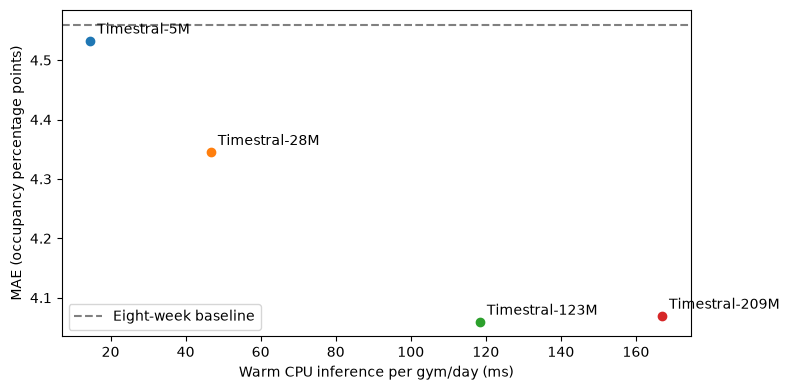

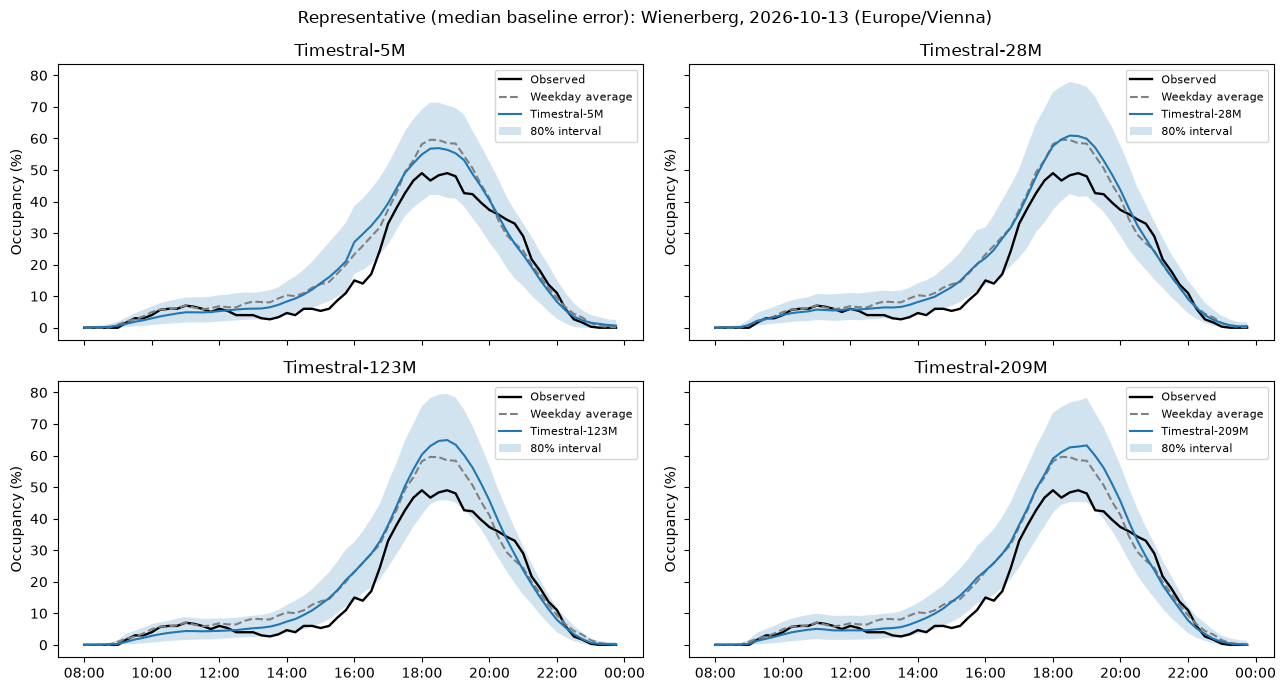

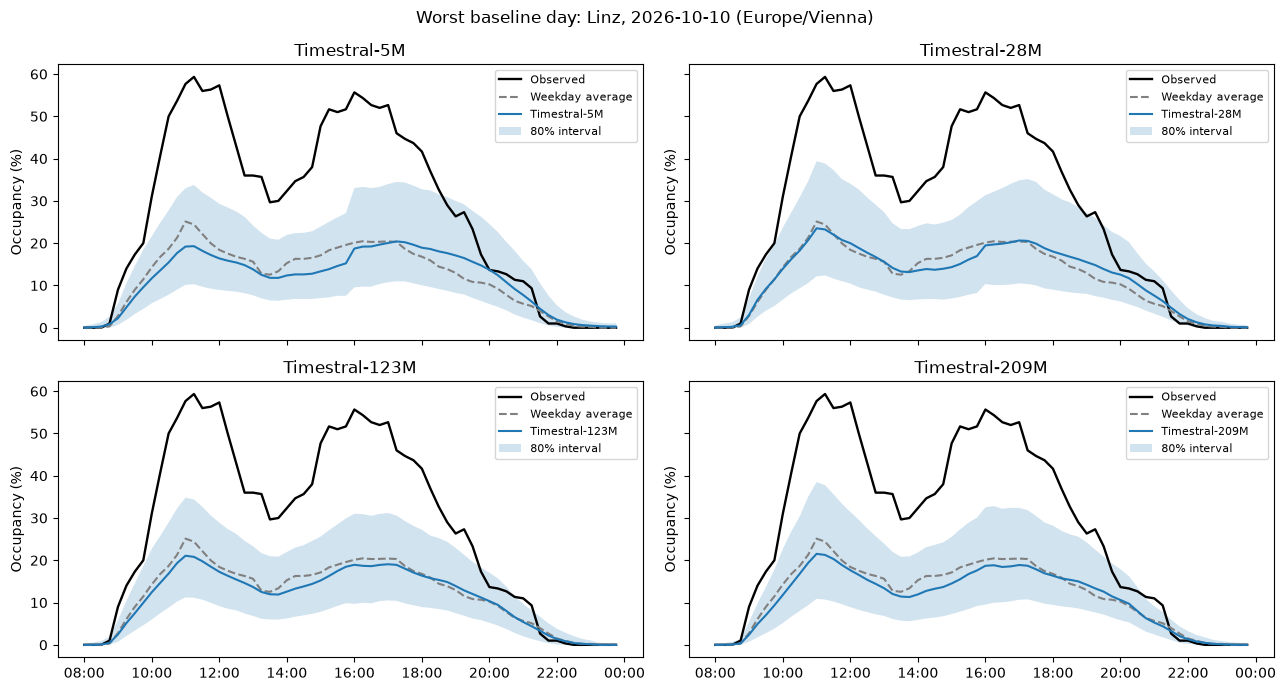

In [8]:
tradeoff = plot_tradeoff(test_table)
tradeoff.savefig(RUN_DIR / "accuracy_vs_runtime.png", dpi=160)
plt.show()
for label, figure in zip(("representative", "worst"), plot_examples(test_cases, test_predictions, test_scores)):
    figure.savefig(RUN_DIR / f"forecast_{label}.png", dpi=160)
    plt.show()

In [9]:
# Export forecasts with timestamps and the exact scoring mask for independent inspection.
rows = []
for method, predictions in test_predictions.items():
    for case, values in zip(test_cases, predictions):
        for t, actual, scored, (low, median, high) in zip(case.times, case.actual, case.mask, values):
            rows.append({"method": method, "location_id": case.location_id, "location": case.title,
                         "origin": case.origin.isoformat(), "timestamp": t.isoformat(),
                         "actual": actual, "scored": bool(scored), "prediction": median,
                         "p10": low if method != BASELINE else np.nan,
                         "p90": high if method != BASELINE else np.nan})
pd.DataFrame(rows).to_csv(RUN_DIR / "test_forecasts.csv", index=False)
print("All results, measurements, logs, and figures:", RUN_DIR)
print("Review the tradeoffs above to choose a model; this notebook makes no automatic selection.")

All results, measurements, logs, and figures: /Users/flo/src/boulderbat/notebooks/results/86d61981513e9be6
Review the tradeoffs above to choose a model; this notebook makes no automatic selection.


## 6. Last complete day: every location

For the last complete local day in the selected dataset window, each chart overlays **observed occupancy**, the **eight-week weekday average**, and the **median forecasts from all four Timestral sizes**. These are the same 08:00 forecasts used in the benchmark; no later readings are used to update them.

Every database location is shown, including locations excluded from the benchmark. If a location lacks eight weeks of preceding history, its observations are shown with the exclusion reason rather than a forecast. Missing or failed model forecasts are identified on the chart. Intervals are omitted here to keep all five prediction lines readable.

Last complete day: 2026-10-22 (Europe/Vienna), forecast issued at 08:00


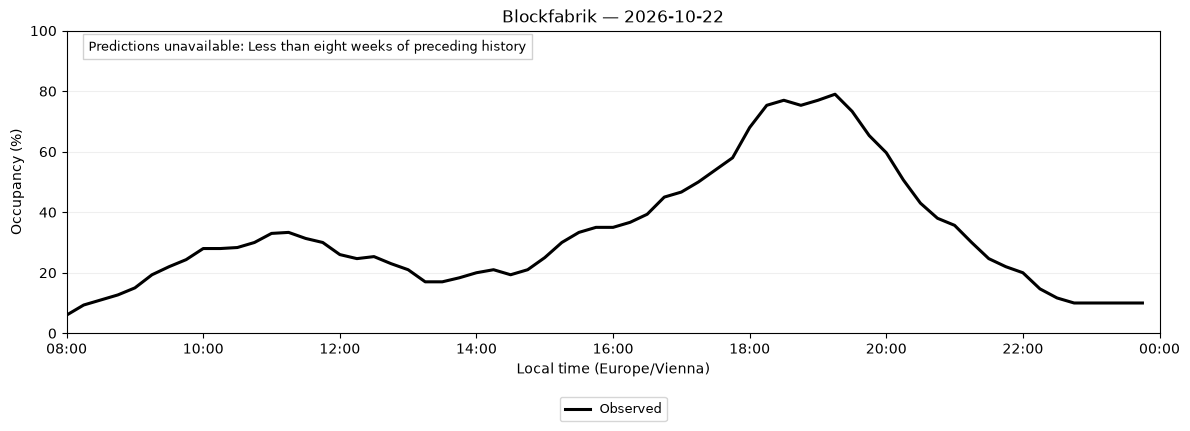

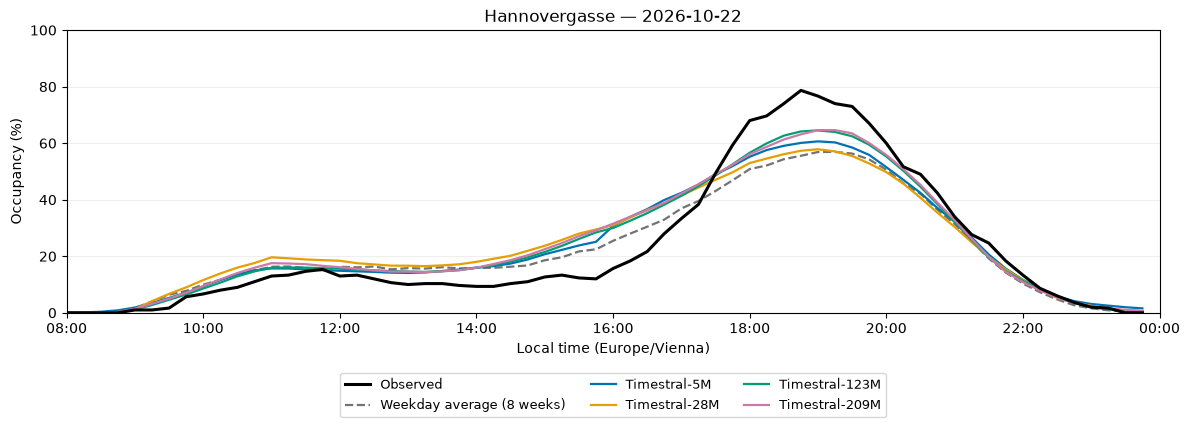

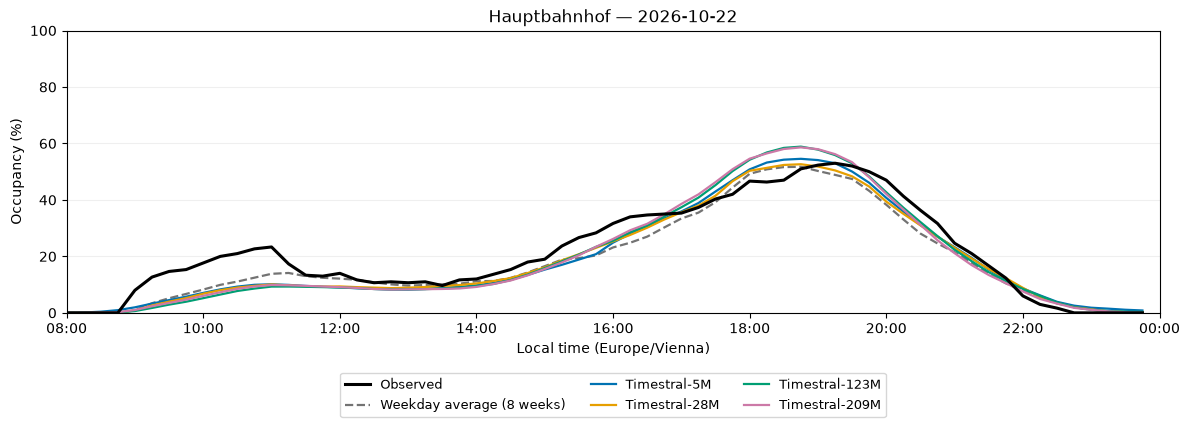

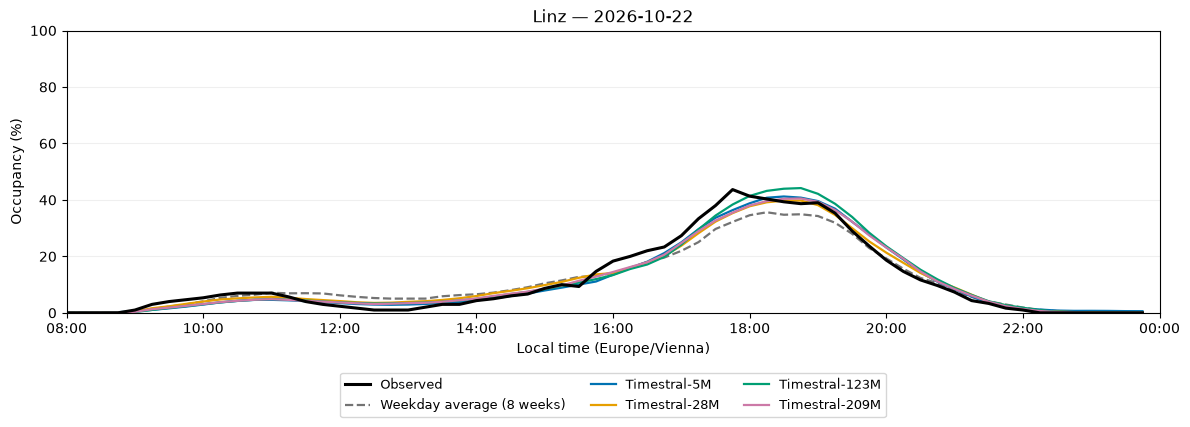

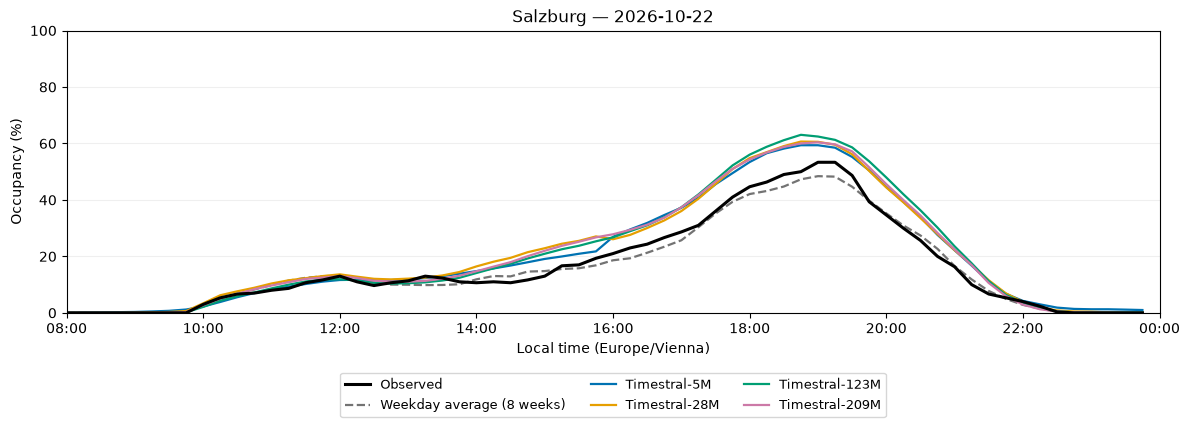

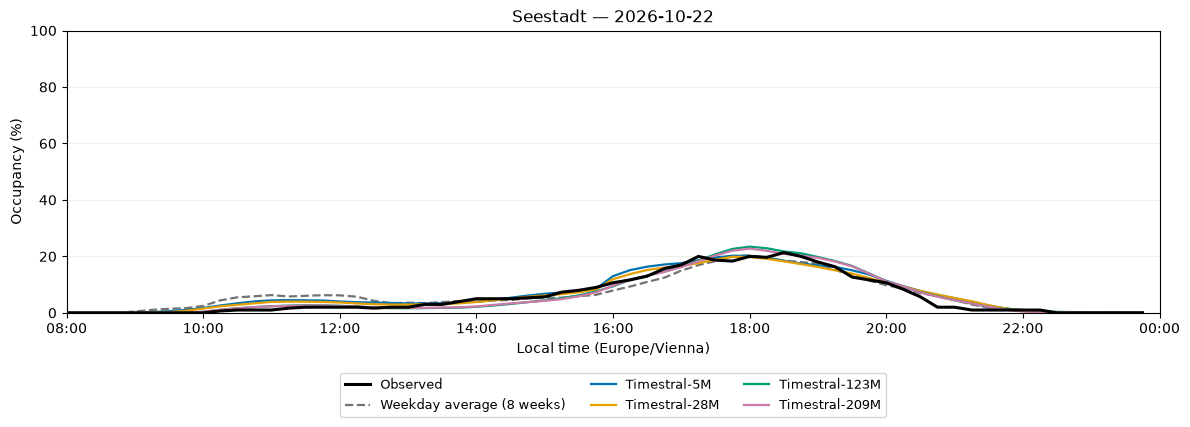

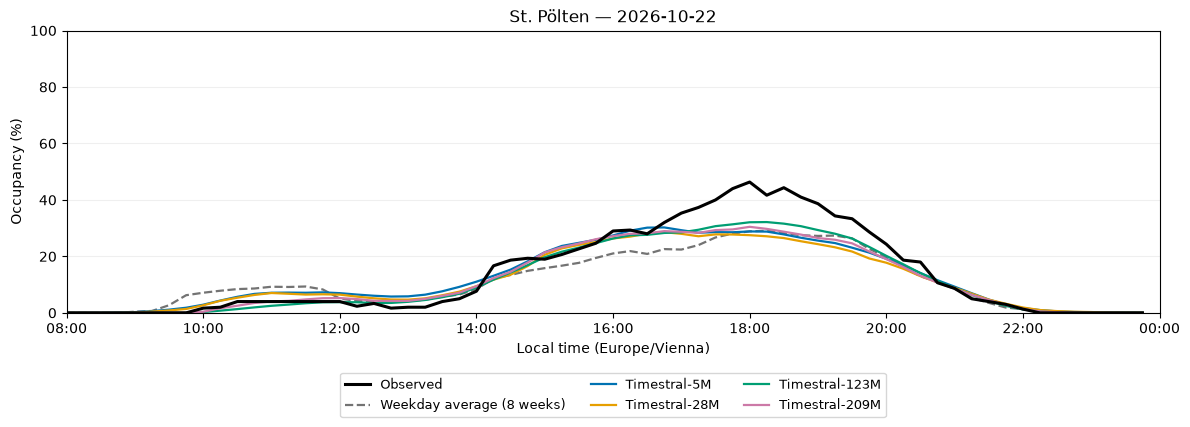

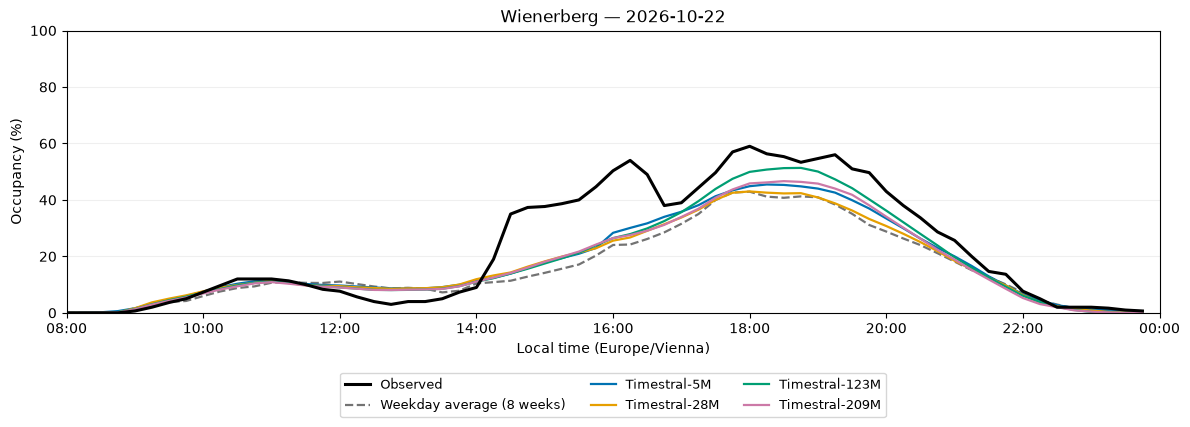

Saved charts: /Users/flo/src/boulderbat/notebooks/results/86d61981513e9be6/last_complete_day


In [10]:
from zoneinfo import ZoneInfo
import matplotlib.dates as mdates

last_day = pd.Timestamp(periods["end_exclusive"], tz="Europe/Vienna") - pd.DateOffset(days=1)
last_day_label = str(last_day.date())
origin = pd.Timestamp(f"{last_day_label} 08:00", tz="Europe/Vienna")
last_times = pd.date_range(origin, last_day + pd.DateOffset(days=1), freq="15min", inclusive="left")
case_indices = {case.location_id: i for i, case in enumerate(test_cases) if case.day == last_day_label}
colors = {BASELINE: "#737373", **dict(zip(MODELS, ("#0072B2", "#E69F00", "#009E73", "#CC79A7")))}
last_day_dir = RUN_DIR / "last_complete_day"
last_day_dir.mkdir(exist_ok=True)
print(f"Last complete day: {last_day_label} (Europe/Vienna), forecast issued at 08:00")

for location in locations.sort_values("title").itertuples(index=False):
    fig, ax = plt.subplots(figsize=(12, 4.5))
    raw = history[history.location_id == location.id].set_index("time").capacity
    observed = raw.resample("15min", label="left", closed="left").mean().reindex(last_times.tz_convert("UTC"))
    ax.plot(last_times, observed.to_numpy(), color="black", linewidth=2.2, label="Observed", zorder=10)
    notes = []
    index = case_indices.get(location.id)
    if index is None:
        reason = "No eligible benchmark case for this day"
        if not exclusions.empty:
            excluded = exclusions[exclusions.location == location.title]
            if "day" in excluded:
                excluded = excluded[excluded.day.isna() | excluded.day.eq(last_day_label)]
            if not excluded.empty:
                reason = "; ".join(excluded.reason.unique())
        notes.append(f"Predictions unavailable: {reason}")
    else:
        for method in METHODS:
            if method not in test_predictions:
                notes.append(f"{method}: forecast unavailable (see test results)")
                continue
            median = test_predictions[method][index, :, 1]
            ax.plot(last_times, median, color=colors[method],
                    linestyle="--" if method == BASELINE else "-", linewidth=1.6, label=method)
    if not observed.notna().any():
        notes.append("No observed readings for this day")
    if notes:
        ax.text(.02, .97, "\n".join(notes), transform=ax.transAxes, va="top", fontsize=9,
                bbox={"facecolor": "white", "edgecolor": "#cccccc", "alpha": .9})
    ax.set(title=f"{location.title} — {last_day_label}", ylabel="Occupancy (%)",
           xlabel="Local time (Europe/Vienna)", ylim=(0, 100),
           xlim=(origin, last_day + pd.DateOffset(days=1)))
    ax.xaxis.set_major_locator(mdates.HourLocator(byhour=range(0, 24, 2), tz=ZoneInfo("Europe/Vienna")))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M", tz=ZoneInfo("Europe/Vienna")))
    ax.grid(axis="y", alpha=.2)
    ax.legend(loc="upper center", bbox_to_anchor=(.5, -.19), ncol=3, fontsize=9)
    fig.tight_layout()
    fig.savefig(last_day_dir / f"{last_day_label}_{location.id}.png", dpi=160, bbox_inches="tight")
    plt.show()
    plt.close(fig)

print("Saved charts:", last_day_dir)